# Adversarial attacks on object detectors

We attack one full-size comma10k frame with the gradient attacks, against two COCO detectors:

| § | Target model | Framework | Adapter (`examples/adapters/`) |
|---|---|---|---|
| 1 | YOLOv8n | PyTorch | `torch_detector_target.py` (any ultralytics detector) |
| 2 | D-FINE nano | TensorFlow / Keras | `keras_detector_target.py` (KerasHub D-FINE or RetinaNet) |

No pretrained Flax detector is available off the shelf, so JAX is only in `adversarial-classification.ipynb`.

kcai only asks a target model for a `name` and `grad(x)`, the gradient of a loss with respect to an image in `[0, 1]`. Each detector adapter implements `grad` with its framework's autograd. Four transformations use that gradient:

- **`fgsm`** (`kcai-data-sampling-fgsm`): kcai's own implementation, `x + ε·sign(grad)`.
- **`art_fgsm`** (`kcai-data-sampling-art`): ART's `FastGradientMethod`; it must give the same image as `fgsm`.
- **`art_pgd`** and **`art_mim`** (`kcai-data-sampling-art`): ART's iterative attacks, many small steps within the same budget.

The black-box attacks (`art_square`, `art_simba`, `art_hopskipjump`) are not used here: they call `predict` and need class scores `(B, n_classes)`, while a detector returns boxes. A detector would need a `predict` that reduces its output to class scores first (see `docs/target-models.md`, *Limits*).

**Environment**: the `kcai` env with `kcai-data-sampling[job,images,fgsm]`, the `-art` package (`pip install -e packages/kcai-data-sampling-art`) and `ultralytics`. §2 needs `tensorflow-cpu` and `keras-hub` (`pip install --no-deps keras-hub kagglehub kagglesdk`: its full `tensorflow` dependency would clash with `tensorflow-cpu`). You also need `yolov8n.pt` at the repository root and the comma10k sample from `scripts/fetch_comma10k_sample.py`.

## Setup

Import `torch` **before** `tensorflow`: the reverse order crashes Python with tensorflow-cpu 2.21 and torchvision 0.29.

In [1]:
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's C++ logs
import torch  # noqa: F401  (before tensorflow, see above)
import torchvision  # noqa: F401

import numpy as np
from PIL import Image

# Work from the repository root, and make the adapters and display helpers importable.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(REPO)
sys.path[:0] = ["examples/adapters", "examples/notebooks"]

from display import show
from kcai_data_sampling_fgsm.api.transformations.fgsm import Fgsm
from kcai_data_sampling_art.api.transformations import ArtFgsm, ArtMim, ArtPgd

Transformations work on batches. Here `x` is a batch of one RGBA `uint8` image, shape `(1, H, W, 4)`, as the kcai dataloader produces it.

`EPSILON` is the attack budget in `[0, 1]` units: 8/255 lets each pixel move by at most 8 grey levels.

(1, 1208, 1928, 4) uint8



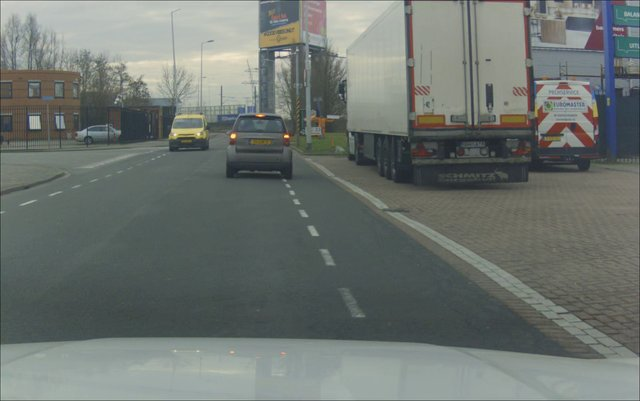

In [2]:
image_path = sorted(Path("examples/data/comma10k_sample/imgs").glob("*.png"))[0]
x = np.asarray(Image.open(image_path).convert("RGBA"))[None]
EPSILON = 8 / 255

print(x.shape, x.dtype)
show([("original", x[0])])

Helpers. `attack` builds a transformation from its config, as a job would, and applies it to `x` (the gradient attacks are deterministic: no random generator). `perturbation` stretches the change for display, since it is invisible at 8 grey levels (grey = unchanged).

In [3]:
def attack(cls, target, **params):
    return cls({"target_model": target, **params}).apply(x, None)


def perturbation(x_adv):
    delta = x_adv[0, ..., :3].astype(int) - x[0, ..., :3]
    return np.clip(128 + delta * 16, 0, 255).astype(np.uint8)

## 1. PyTorch detector: YOLOv8n

`TorchDetectorTarget.grad` backpropagates minus the total confidence of the detections YOLO reports (scores above 0.25). Increasing that loss lowers the confidence, so the attacks try to make objects disappear.

First, the local `fgsm` and ART's `art_fgsm` on the same target model: they must give **the same image**.

In [4]:
from torch_detector_target import TorchDetectorTarget

yolo = TorchDetectorTarget(weights="yolov8n.pt")

x_fgsm = attack(Fgsm, yolo, epsilon=EPSILON)
x_art_fgsm = attack(ArtFgsm, yolo, epsilon=EPSILON)
print("same image as fgsm:", np.array_equal(x_fgsm, x_art_fgsm))

same image as fgsm: True


Then the iterative attacks, at the same budget. `art_pgd` takes `max_iter` (10) steps of `step_fraction * epsilon` (a quarter), each projected back into the budget; `art_mim` adds momentum (`decay`). PGD's random start is off: ART only allows it on classifiers.

In [5]:
yolo_adversarial = {
    "art_fgsm": x_art_fgsm,
    "art_pgd": attack(ArtPgd, yolo, epsilon=EPSILON),
    "art_mim": attack(ArtMim, yolo, epsilon=EPSILON),
}

Do they fool the detector? We run YOLO on the original and attacked images.


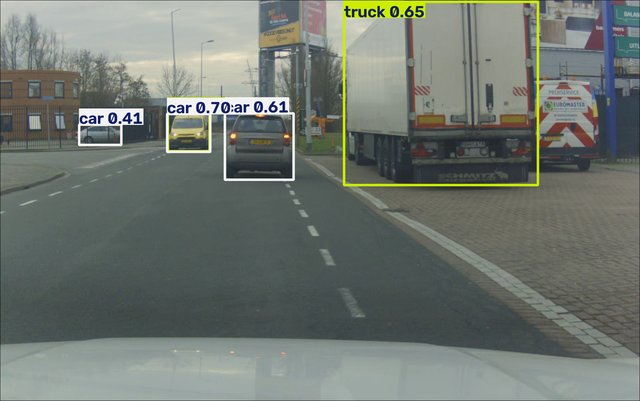
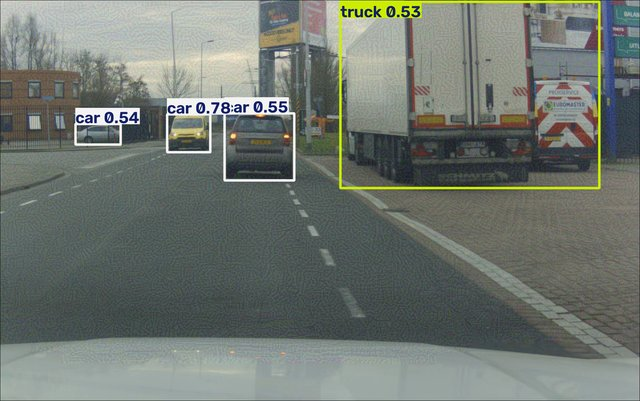


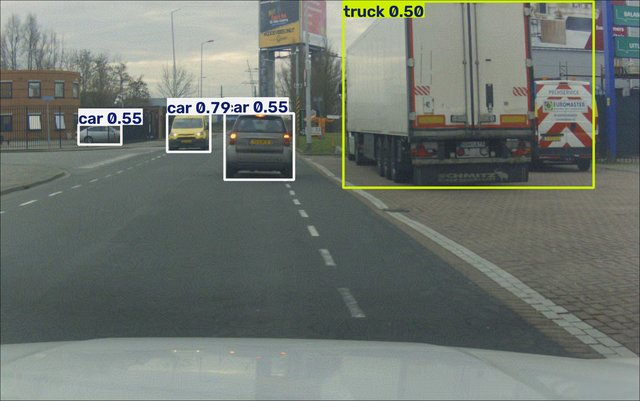
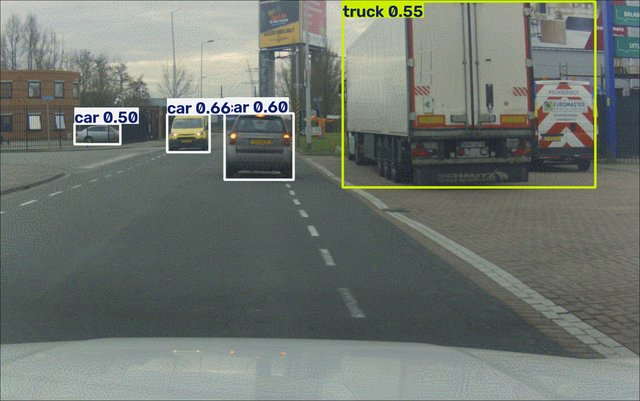

In [6]:
from ultralytics import YOLO

detector = YOLO("yolov8n.pt")


def detect(batch):
    result = detector.predict(Image.fromarray(batch[0, ..., :3]), conf=0.25, verbose=False)[0]
    return len(result.boxes), result.plot()[..., ::-1]  # plot() draws in BGR


panels = []
for name, batch in {"original": x, **yolo_adversarial}.items():
    n, boxes = detect(batch)
    panels.append((f"{name}: {n} detections", boxes))
show(panels[:2])
show(panels[2:])

At 8 grey levels, each attack removes one of the five detections. On YOLOv8n, ten PGD or MIM steps do no better than one FGSM step.

## 2. TensorFlow detector: KerasHub D-FINE

`KerasDetectorTarget` works with KerasHub's COCO detectors, chosen by preset name; here the smallest D-FINE. As for YOLO, the detector's own `predict` ends with non-maximum suppression, which has no gradient, so `grad` reads the network's raw class scores and backpropagates minus the total confidence of the detections above 0.5, with `tf.GradientTape`.

In [7]:
from keras_detector_target import KerasDetectorTarget

dfine = KerasDetectorTarget(weights="dfine_nano_coco")  # KerasHub downloads the weights on first use

x_fgsm = attack(Fgsm, dfine, epsilon=EPSILON)
dfine_adversarial = {
    "art_fgsm": attack(ArtFgsm, dfine, epsilon=EPSILON),
    "art_pgd": attack(ArtPgd, dfine, epsilon=EPSILON),
    "art_mim": attack(ArtMim, dfine, epsilon=EPSILON),
}
print("same image as fgsm:", np.array_equal(x_fgsm, dfine_adversarial["art_fgsm"]))

I0000 00:00:1792416515.632085  198628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792416524.951308  198628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


same image as fgsm: True


Do they fool the detector? The adapter sees the whole frame resized to 640×640, so we detect on that same view and draw the boxes back on the full image. D-FINE uses the COCO classes in the same order as YOLO.


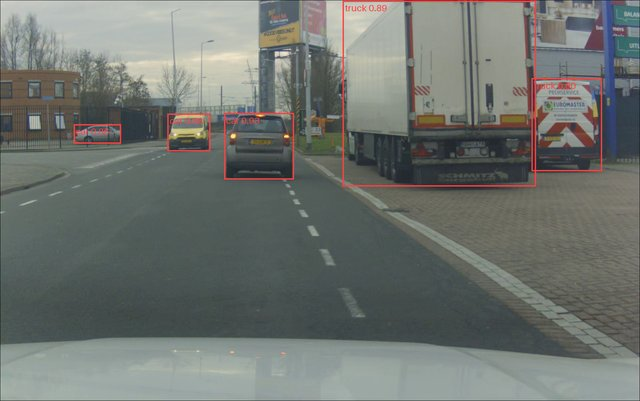
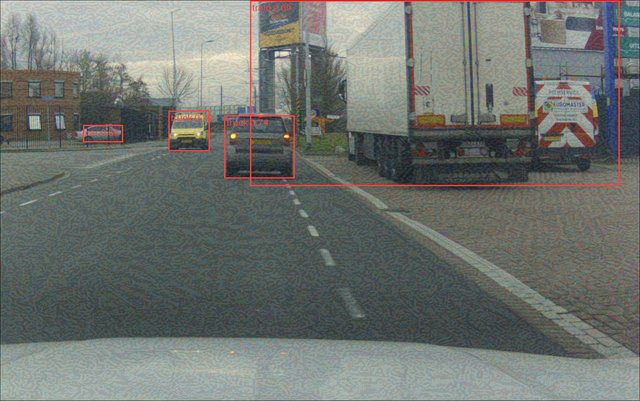


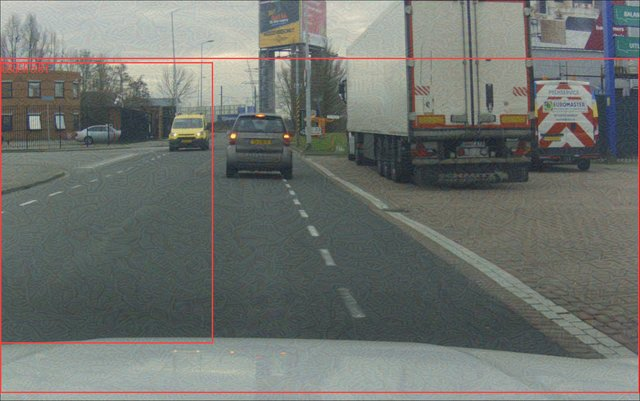
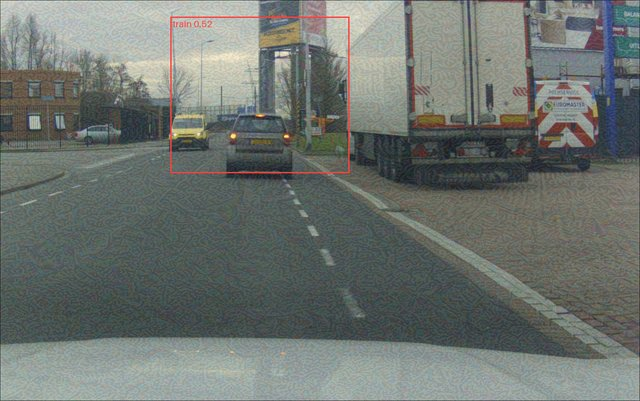

In [8]:
from PIL import ImageDraw


def detect_dfine(batch):
    height, width = batch.shape[1:3]
    resized = dfine.tf.image.resize(batch[..., :3].astype(np.float32), dfine.input_size, antialias=True)
    found = dfine.model.predict(resized, verbose=0)  # decoding + non-maximum suppression
    n = int(found["num_detections"][0])
    image = Image.fromarray(batch[0, ..., :3])
    draw = ImageDraw.Draw(image)
    sy, sx = height / dfine.input_size[0], width / dfine.input_size[1]
    for (y0, x0, y1, x1), label, score in zip(found["boxes"][0][:n], found["labels"][0][:n], found["confidence"][0][:n]):
        draw.rectangle([x0 * sx, y0 * sy, x1 * sx, y1 * sy], outline=(255, 64, 64), width=4)
        draw.text((x0 * sx + 6, y0 * sy + 4), f"{detector.names[int(label)]} {score:.2f}", fill=(255, 64, 64), font_size=28)
    return n, np.asarray(image)


panels = []
for name, batch in {"original": x, **dfine_adversarial}.items():
    n, boxes = detect_dfine(batch)
    panels.append((f"{name}: {n} detections", boxes))
show(panels[:2])
show(panels[2:])

On D-FINE the iterative attacks pay off: one FGSM step removes one of the five detections, PGD leaves two and MIM only one, within the same 8 grey levels.

## 3. What the attacks change

The perturbations of the three ART attacks on YOLOv8n, stretched ×16 (grey = unchanged). All stay within 8 grey levels.

art_fgsm  max change: 8 grey levels
art_pgd   max change: 8 grey levels


art_mim   max change: 8 grey levels



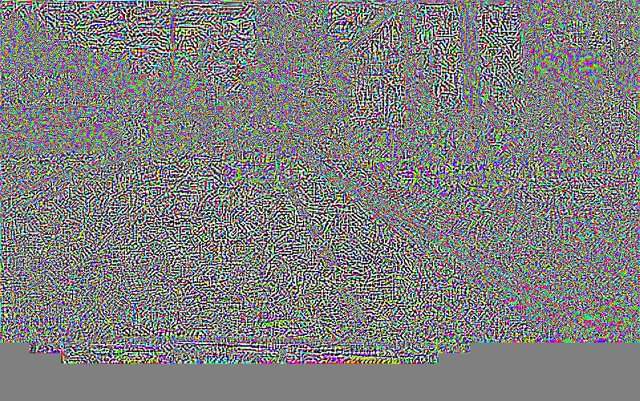
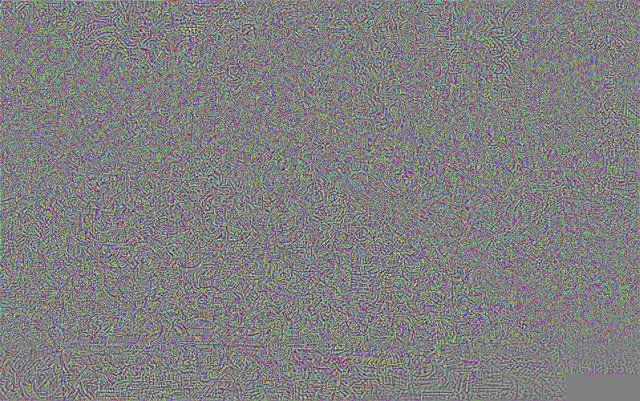
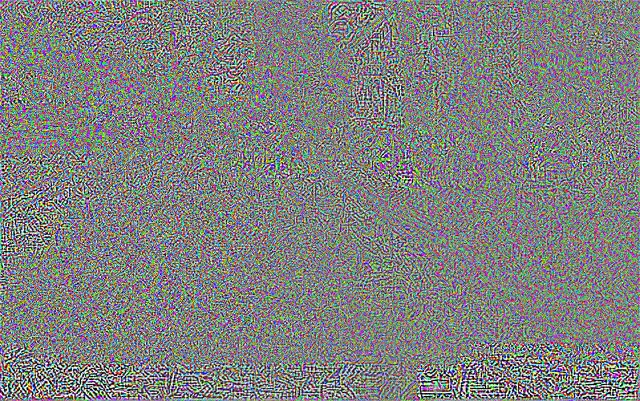

In [9]:
for name, batch in yolo_adversarial.items():
    print(f"{name:<9} max change: {np.abs(batch.astype(int) - x).max()} grey levels")
show([(name, perturbation(batch)) for name, batch in yolo_adversarial.items()])

## Takeaways

- **`fgsm` and `art_fgsm` give the same image** on both detectors, in PyTorch and TensorFlow.
- **The same attack and budget do not break every detector alike.** Iterative attacks bring D-FINE from five detections to one, but YOLOv8n only from five to four, like one FGSM step. The strength depends on the model and on the adapter's loss as much as on the attack.
- **Detectors' `predict` (decoding + non-maximum suppression) has no gradient**: the adapters read the raw class scores instead, and their loss is minus the total confidence.
- **Only the gradient attacks apply.** The black-box attacks need class scores `(B, n_classes)`; a detector would need a `predict` that reduces its boxes to scores first.
- **Iterative attacks multiply the cost by `max_iter`**: about 20 gradients per attack. On full-size frames that took 30 seconds on YOLOv8n and about 3.5 minutes on D-FINE, on a CPU.